# Random Forest profitability model

This notebook uses a simple sequence: load data, split data, fill missing values, train a Random Forest, choose a validation threshold, evaluate the test data, and plot the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, average_precision_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
import preprocessing

## Load and inspect the prepared records

The CSV contains 134 predictor columns and the binary `profitable` target. Profit is 1 and Loss is 0. The classes are balanced because the source data was undersampled.

In [2]:
df = pd.read_csv("../dataset/50-50undersampled.csv", low_memory=False)
X = df.drop(columns=["profitable"])
y = df["profitable"]
print("Feature shape:", X.shape)
print("Class balance:\n", y.value_counts())

Feature shape: (549174, 19)
Class balance:
 profitable
0    274587
1    274587
Name: count, dtype: int64


## Create training and test sets

The test set is held out until the end. Stratification keeps the Profit/Loss proportions consistent.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=preprocessing.TEST_SIZE, random_state=preprocessing.RANDOM_STATE, stratify=y)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 439339
Test rows: 109835


In [4]:
preprocessor = ColumnTransformer(
    transformers=[("median_imputer", SimpleImputer(strategy="median"), make_column_selector(dtype_include="number"))],
    remainder="passthrough",
)

## Fill missing values and train the Random Forest

In order to fine tune the parameters that were used in the RandomForestClassifier function, a RandomizedSearchCV was first used to compare different combinations such as the number of trees, the maximum depth, and the minimum rows needed to justify a leaf prediction. 12 randomly selected combinations of settings were attempted, each implementing k-fold validation to compare the probability ranking of each forest. Based on those results, the following parameters were chosen for faster training time on future tweaks.

The active model uses the previously selected values: 250 trees, depth 24, leaf 20, split 40, max_features 0.25, Gini criterion, and max_samples 0.5.

The code can be viewed in the commented cell below. It is currently commented so the other code can be run as simply as possible.

In [ ]:
# search_pipeline = Pipeline([
#     ("preprocessor", preprocessor),
#     ("model", RandomForestClassifier(bootstrap=True, max_samples=0.5, random_state=preprocessing.RANDOM_STATE, n_jobs=-1)),
# ])
# settings_to_test = {
#     "model__n_estimators": [150, 250],  # Number of trees.
#     "model__max_depth": [8, 12, 16],  # Maximum depth of each tree.
#     "model__min_samples_leaf": [50, 100, 200],  # Minimum rows in a leaf.
#     "model__min_samples_split": [100, 250, 500],  # Minimum rows needed to split.
#     "model__max_features": ["sqrt", 0.10, 0.15],  # Features considered at each split.
#     "model__criterion": ["gini", "entropy"],  # Split-quality formula.
# }
# search = RandomizedSearchCV(
#     search_pipeline,
#     settings_to_test,
#     n_iter=24,  # Try n_iter randomly selected combinations.
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=preprocessing.RANDOM_STATE),
#     scoring="average_precision",  # Compare probability ranking with AP.
#     random_state=preprocessing.RANDOM_STATE,
#     n_jobs=1,  # Each forest already uses all available cores.
#     refit=False,
# )
# search.fit(X_train, y_train)
# print("Best parameters:", search.best_params_)

## Cross-validation metrics

The Random Forest pipeline is evaluated with the same five stratified folds used by GaussianNB and Decision Tree. The imputer is fit independently inside each fold, so validation-fold values never contribute medians to training.

In [6]:
k = 5
kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=preprocessing.RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

def run_cv(model):
    """Run k-fold cross-validation and return a table with one row per fold."""
    results = cross_validate(model, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    table = pd.DataFrame({"Fold": range(1, k + 1)})
    for metric in scoring:
        table["Train " + metric] = results["train_" + metric]
        table["Val " + metric] = results["test_" + metric]
    return table.set_index("Fold")

def summarize(folds):
    return pd.DataFrame({
        "Mean": folds.mean(),
        "Std. deviation": folds.std(ddof=0),
    })

def mean_std_table(folds):
    return folds.apply(lambda col: f"{col.mean():.3f} \u00b1 {col.std(ddof=0):.3f}")

rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=50,
        min_samples_split=100,
        max_features="sqrt",
        criterion="gini",
        max_samples=0.5,
        bootstrap=True,
        random_state=preprocessing.RANDOM_STATE,
        n_jobs=-1,
    )),
])

rf_folds = run_cv(rf_pipe)
rf_folds

,Train accuracy,Val accuracy,Train precision,Val precision,Train recall,Val recall,Train f1,Val f1,Train roc_auc,Val roc_auc,Train average_precision,Val average_precision
Fold,,,,,,,,,,,,
1,0.684890,0.667888,0.687442,0.671129,0.678085,0.658419,0.682732,0.664713,0.753393,0.731064,0.750691,0.725940
2,0.684975,0.667035,0.687771,0.669016,0.677533,0.661174,0.682614,0.665072,0.753620,0.729474,0.750852,0.724551
3,0.685422,0.665373,0.687643,0.666927,0.679508,0.660718,0.683551,0.663808,0.754220,0.727778,0.751381,0.722614
4,0.685212,0.666932,0.688868,0.671379,0.675536,0.653958,0.682137,0.662554,0.754218,0.727375,0.751674,0.719958
5,0.684339,0.668681,0.686814,0.670344,0.677715,0.663814,0.682234,0.667063,0.753257,0.731614,0.750252,0.727246


In [7]:
summarize(rf_folds)

,Mean,Std. deviation
Train accuracy,0.684968,0.000365
Val accuracy,0.667182,0.001105
Train precision,0.687708,0.000667
Val precision,0.669759,0.001638
Train recall,0.677676,0.001275
Val recall,0.659617,0.003308
Train f1,0.682654,0.000501
Val f1,0.664642,0.001490
Train roc_auc,0.753742,0.000407
Val roc_auc,0.729461,0.001697


In [8]:
comparison_cv = pd.DataFrame({
    "Random Forest": mean_std_table(rf_folds),
})
comparison_cv

,Random Forest
Train accuracy,0.685 ± 0.000
Val accuracy,0.667 ± 0.001
Train precision,0.688 ± 0.001
Val precision,0.670 ± 0.002
Train recall,0.678 ± 0.001
Val recall,0.660 ± 0.003
Train f1,0.683 ± 0.001
Val f1,0.665 ± 0.001
Train roc_auc,0.754 ± 0.000
Val roc_auc,0.729 ± 0.002


In [9]:
rf_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('median_imputer', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If

## Optional precision-oriented threshold

This threshold tuning is commented out. The active test evaluation uses the default 0.5 threshold through `predict`, matching the GaussianNB and Decision Tree approach.

In [10]:
# Optional threshold tuning can be added here using out-of-fold probabilities.

## Evaluate the held-out test data

After cross-validation has selected parameters, the pipeline can be trained as follows.

The preprocessor is part of the pipeline, so it learns imputation medians only from training data and applies them to the held-out test set.

In [11]:
rf_pipe.fit(X_train, y_train)

test_probability = rf_pipe.predict_proba(X_test)[:, 1]
test_prediction = rf_pipe.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, test_prediction), 4))
print("Precision:", round(precision_score(y_test, test_prediction, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_prediction, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_prediction, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probability), 4))
print("Average precision:", round(average_precision_score(y_test, test_probability), 4))

Accuracy: 0.6674
Precision: 0.6704
Recall: 0.6585
F1-score: 0.6644
ROC-AUC: 0.7292
Average precision: 0.7242


## Plot the test results

The first three plots show classification performance. The fourth plot shows which features the Random Forest used most often to split the data. Feature importance is not proof that a feature causes profitability.

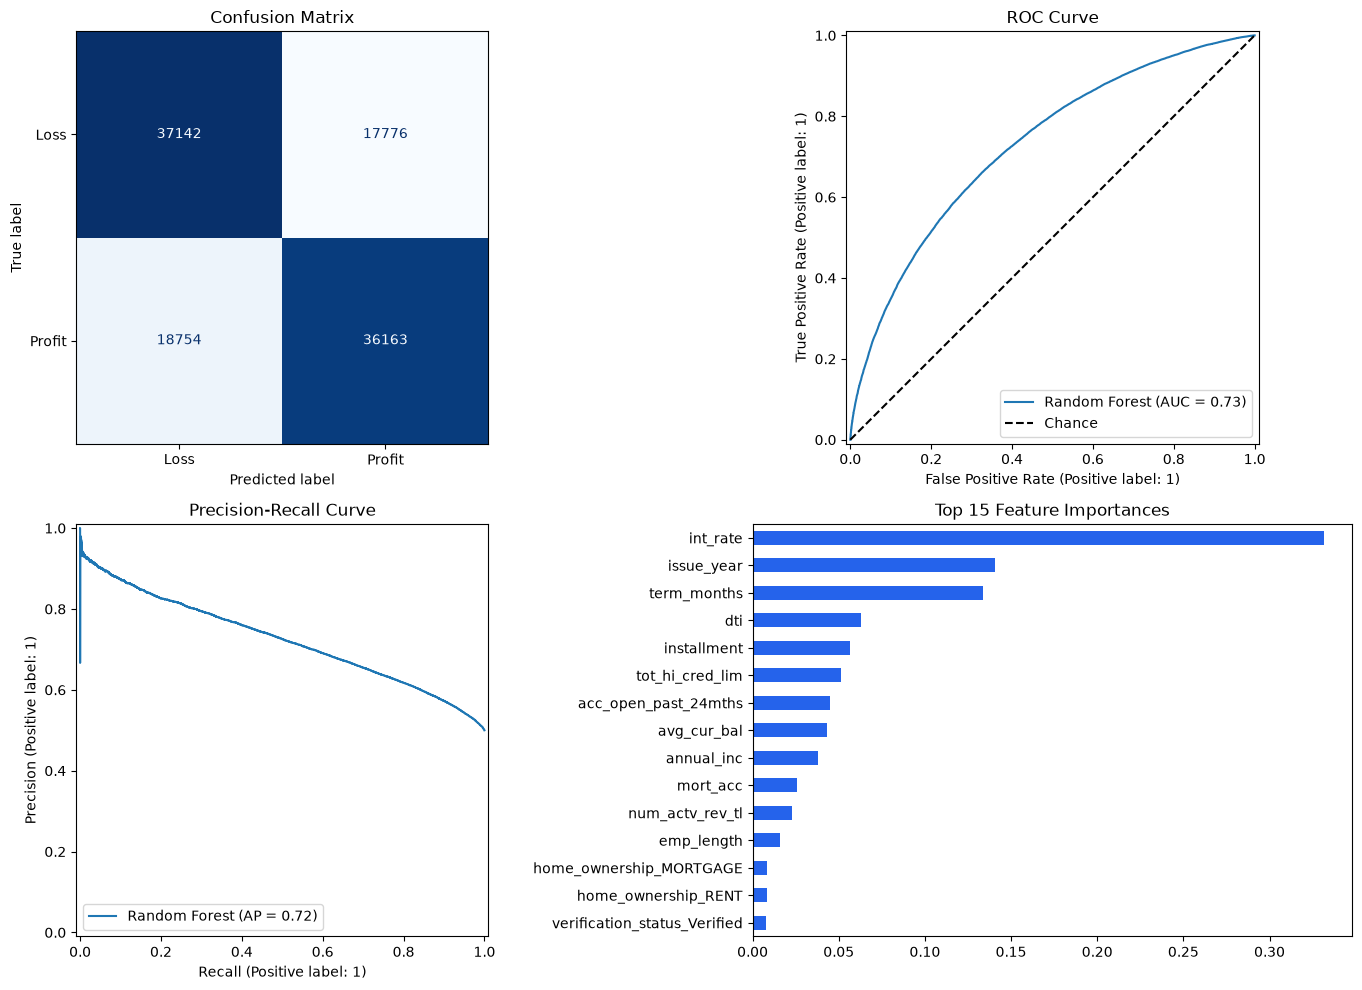

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["Loss", "Profit"], cmap="Blues", colorbar=False, ax=axes[0, 0])
axes[0, 0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, name="Random Forest", ax=axes[0, 1])
axes[0, 1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0, 1].legend()
axes[0, 1].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, test_probability, name="Random Forest", ax=axes[1, 0])
axes[1, 0].set_title("Precision-Recall Curve")
feature_importance = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=X.columns).sort_values(ascending=False).head(15).sort_values()
feature_importance.plot(kind="barh", color="#2563eb", ax=axes[1, 1])
axes[1, 1].set_title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [13]:
print(confusion_matrix(y_test, test_prediction))

[[37142 17776]
 [18754 36163]]


In [14]:
len(y_test)

109835